# **Get the Data**

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("student_habits_performance.csv")

# **Data Quick Look**

In [3]:
data.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   object 
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   object 
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   object 
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   object 
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    object 
 12  internet_quality               1000 non-null   ob

In [5]:
data.describe()

,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
count,1000.0000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.4980,3.55010,2.505500,1.819700,84.131700,6.470100,3.042000,5.438000,69.601500
std,2.3081,1.46889,1.172422,1.075118,9.399246,1.226377,2.025423,2.847501,16.888564
min,17.0000,0.00000,0.000000,0.000000,56.000000,3.200000,0.000000,1.000000,18.400000
25%,18.7500,2.60000,1.700000,1.000000,78.000000,5.600000,1.000000,3.000000,58.475000
50%,20.0000,3.50000,2.500000,1.800000,84.400000,6.500000,3.000000,5.000000,70.500000
75%,23.0000,4.50000,3.300000,2.525000,91.025000,7.300000,5.000000,8.000000,81.325000
max,24.0000,8.30000,7.200000,5.400000,100.000000,10.000000,6.000000,10.000000,100.000000


In [6]:
data.isnull().sum()

student_id                        0
age                               0
gender                            0
study_hours_per_day               0
social_media_hours                0
netflix_hours                     0
part_time_job                     0
attendance_percentage             0
sleep_hours                       0
diet_quality                      0
exercise_frequency                0
parental_education_level         91
internet_quality                  0
mental_health_rating              0
extracurricular_participation     0
exam_score                        0
dtype: int64

In [7]:
data["parental_education_level"].unique()

array(['Master', 'High School', 'Bachelor', nan], dtype=object)

In [8]:
data["diet_quality"].unique()

array(['Fair', 'Good', 'Poor'], dtype=object)

In [9]:
data["extracurricular_participation"].unique()

array(['Yes', 'No'], dtype=object)

# **Data Visualization**

In [10]:
import matplotlib.pyplot as mtp
import numpy as np

<Axes: xlabel='study_hours_per_day', ylabel='exam_score'>

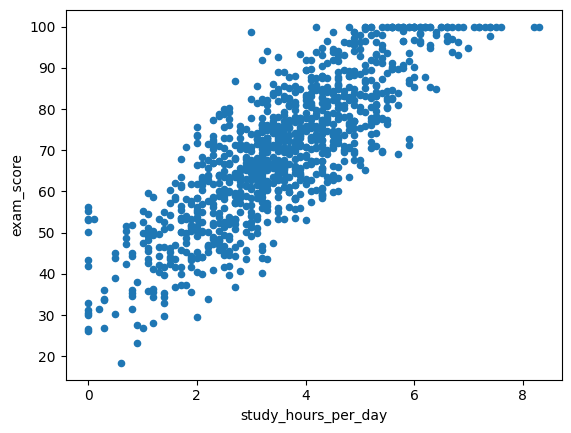

In [11]:
data.plot(x="study_hours_per_day",y="exam_score",kind="scatter")

<BarContainer object of 480 artists>

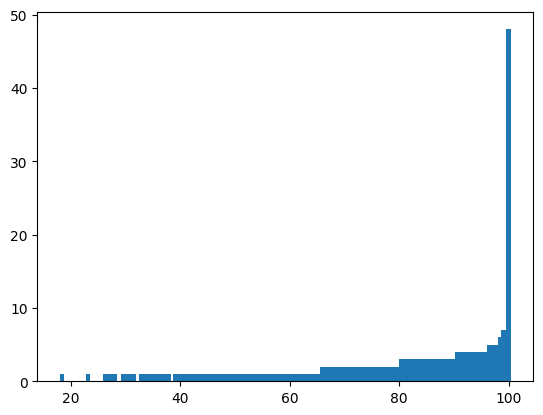

In [12]:
mtp.bar(x=np.sort(data["exam_score"].unique()), height=np.sort(data["exam_score"].value_counts()))

# **Feature Engineering**

In [13]:
corr = data.corr(numeric_only=True)
corr["exam_score"].sort_values(ascending=False)

exam_score               1.000000
study_hours_per_day      0.825419
mental_health_rating     0.321523
exercise_frequency       0.160107
sleep_hours              0.121683
attendance_percentage    0.089836
age                     -0.008907
social_media_hours      -0.166733
netflix_hours           -0.171779
Name: exam_score, dtype: float64

In [14]:
data["study_to_sleep"] = data["study_hours_per_day"] / data["sleep_hours"]
data["study_to_attendance"] = data["study_hours_per_day"] / data["attendance_percentage"]

In [15]:
corr2 = data.corr(numeric_only=True)
corr2["exam_score"].sort_values(ascending=False)

exam_score               1.000000
study_hours_per_day      0.825419
study_to_attendance      0.769589
study_to_sleep           0.666199
mental_health_rating     0.321523
exercise_frequency       0.160107
sleep_hours              0.121683
attendance_percentage    0.089836
age                     -0.008907
social_media_hours      -0.166733
netflix_hours           -0.171779
Name: exam_score, dtype: float64

In [16]:
data.select_dtypes("object").columns

Index(['student_id', 'gender', 'part_time_job', 'diet_quality',
       'parental_education_level', 'internet_quality',
       'extracurricular_participation'],
      dtype='object')

In [17]:
data["gender"].unique(), data["part_time_job"].unique(), data["diet_quality"].unique(), data["parental_education_level"].unique(), data["internet_quality"].unique(), data["extracurricular_participation"].unique()

(array(['Female', 'Male', 'Other'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['Fair', 'Good', 'Poor'], dtype=object),
 array(['Master', 'High School', 'Bachelor', nan], dtype=object),
 array(['Average', 'Poor', 'Good'], dtype=object),
 array(['Yes', 'No'], dtype=object))

# **Train Test Split**

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X = data.drop(columns=["student_id","exam_score"])
y = data["exam_score"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [20]:
len(X_train), len(X_test)

(800, 200)

In [21]:
len(y_train), len(y_test)

(800, 200)

# **Preprocessing**

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer

In [23]:
num_pipeline = Pipeline([
    ("Scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("Imputer", SimpleImputer(strategy="most_frequent")),
    ("Encoder", OrdinalEncoder())
])

In [24]:
num_column = X.select_dtypes(include="number").columns

In [25]:
cat_column = X.select_dtypes(include="object").columns

In [26]:
preprocessing = ColumnTransformer([
    ("num",num_pipeline,num_column),
    ("cat",cat_pipeline,cat_column)
])

# **Model**

In [27]:
from sklearn.tree import DecisionTreeRegressor

In [28]:
model = Pipeline([
    ("preprocessing",preprocessing),
    ("model", DecisionTreeRegressor(random_state=42))
])

In [29]:
model.fit(X_train,y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [30]:
from sklearn.metrics import root_mean_squared_error

In [31]:
y_pred = model.predict(X_test)
root_mean_squared_error(y_test, y_pred)

9.153966353444828